# Wood Beam
**NDS 2024 (ASD or LRFD) · NDS Supplement 2024 · ASCE 7-22 load combinations · IBC 2024 deflection limits**

Sawn lumber (DF-L, Hem-Fir, SPF, Southern Pine, DF-L timbers), DF glulam (24F-V4, 24F-V8), or
generic LVL/PSL. Supports single-span, cantilever, overhang, fixed-end, or continuous beams.
Checks bending (with beam stability factor CL per unbraced segment), shear, support bearing, and
deflection (with optional creep factor Kcr). Sets CD (ASD) or time effect factor λ (LRFD) for
each load combination, with optional auto-selection of the smallest passing size.

**How to use:** Run the **Engine** cell once, edit the form fields below, and run **Runtime → Run all** (`Ctrl+F9` / `⌘F9`).

> Design aid only. A licensed engineer must verify all inputs and results.
> LVL/PSL values are generic — verify them against the manufacturer's evaluation report.

In [1]:
#@title Engine — run this cell first (embedded structcalc library) { display-mode: "form" }
# Unpacks the embedded structcalc library and imports it (no pip install or Drive mount needed).
# Source: structural-calculations (lib/structcalc). Rebuild notebooks with: python build.py
import base64 as _b64, io as _io, os as _os, sys as _sys, tempfile as _tf, zipfile as _zf
_ZIP = (
    "..."
)
_dir = _os.path.join(_tf.gettempdir(), "structcalc_476d0793fd")
if not _os.path.isdir(_os.path.join(_dir, "structcalc")):
    _zf.ZipFile(_io.BytesIO(_b64.b64decode(_ZIP))).extractall(_dir)
for _m in [m for m in _sys.modules if m == "structcalc" or m.startswith("structcalc.")]:
    del _sys.modules[_m]
if _dir not in _sys.path:
    _sys.path.insert(0, _dir)
import structcalc
print(f"structcalc {structcalc.__version__} ready (build 476d0793fd)")

structcalc 0.1.0 ready (build 476d0793fd)


In [2]:
#@title 1. Member and material
size = "2x12"  #@param {type:"string"}
material = "Sawn lumber"  #@param ["Sawn lumber", "Glulam", "LVL 1.9E (generic)", "LVL 2.0E (generic)", "PSL 2.2E (generic)"]
species = "DF-L"  #@param ["DF-L", "Hem-Fir", "SPF", "Southern Pine"]
grade = "No.2"  #@param ["Select Structural", "No.1", "No.2", "No.3", "Stud", "24F-V4", "24F-V8"]
method = "ASD"  #@param ["ASD", "LRFD"]
auto_select = False  #@param {type:"boolean"}
#@markdown Size examples: `2x10`, `(3)2x12` (multi-ply), `6x12` (timber), `5.125x18` (glulam, actual in.), `(2)1.75x11.875` (LVL).
#@markdown Glulam: choose grade 24F-V4 or 24F-V8. Species applies to sawn lumber only.

In [3]:
#@title 2. Service conditions
wet_service = False  #@param {type:"boolean"}
temperature = "T <= 100F"  #@param ["T <= 100F", "100F < T <= 125F", "125F < T <= 150F"]
incised = False  #@param {type:"boolean"}
repetitive = True  #@param {type:"boolean"}
#@markdown *repetitive*: applies Cr = 1.15 for 3 or more 2x–4x members spaced ≤ 24 in. o.c. and joined by load-distributing elements.

In [4]:
#@title 3. Geometry and bracing
span_type = "Simple span"  #@param ["Simple span", "Cantilever", "Overhang one end (right)", "Overhang both ends", "Fixed-fixed", "Fixed-pinned (propped)", "Custom supports"]
span = 14.0  #@param {type:"number"}
overhang_left = 0.0  #@param {type:"number"}
overhang_right = 0.0  #@param {type:"number"}
custom_supports = "0:pin, 12:pin, 24:pin"  #@param {type:"string"}
bracing = "Continuous (compression edge braced)"  #@param ["Continuous (compression edge braced)", "Top edge braced (sheathing on top)", "At supports only", "At interval"]
brace_interval = 4.0  #@param {type:"number"}
le_load = "general"  #@param ["general", "uniform", "center_point"]
bearing_length = 3.5  #@param {type:"number"}
#@markdown Lengths in ft, bearing length in in. *le_load* selects the NDS Table 3.3.3 effective length row ("general" is conservative).

In [5]:
#@title 4. Loads (service level, + down)
#@markdown Full-length uniform loads in **plf** (default: 2x12 floor joist at 16 in. o.c., 15 psf D / 40 psf L):
w_D = 20.0  #@param {type:"number"}
w_L = 55.0  #@param {type:"number"}
w_Lr = 0.0  #@param {type:"number"}
w_S = 0.0  #@param {type:"number"}
w_W = 0.0  #@param {type:"number"}
self_weight = True  #@param {type:"boolean"}
density_pcf = 35.0  #@param {type:"number"}
#@markdown Extra loads (separate with `;`): `P, x, kip, case` · `w, x1, x2, kip/ft, case` · `t, x1, x2, w1, w2, case` · `M, x, kip-ft, case`
extra_loads = ""  #@param {type:"string"}
live_defl_limit = 360  #@param {type:"integer"}
total_defl_limit = 240  #@param {type:"integer"}
Kcr = 1.0  #@param {type:"number"}
#@markdown *Kcr* (NDS 3.5.2) multiplies dead-load deflection in the total check: 1.5 seasoned lumber/glulam/SCL (dry), 2.0 wet. Use 1.0 to ignore creep.

In [6]:
#@title 5. Reference value overrides (psi, 0 = use table)
Fb = 0  #@param {type:"number"}
Ft = 0  #@param {type:"number"}
Fv = 0  #@param {type:"number"}
Fc_perp = 0  #@param {type:"number"}
Fc = 0  #@param {type:"number"}
E = 0  #@param {type:"number"}
Emin = 0  #@param {type:"number"}

In [7]:
#@title 6. Calculate
from structcalc.calcs import wood_beam

out = wood_beam.run(
    size=size, auto_select=auto_select, material=material, species=species, grade=grade,
    method=method, span_type=span_type, span=span, overhang_left=overhang_left,
    overhang_right=overhang_right, custom_supports=custom_supports,
    w={"D": w_D / 1000, "L": w_L / 1000, "Lr": w_Lr / 1000, "S": w_S / 1000, "W": w_W / 1000},
    extra_loads=extra_loads, self_weight=self_weight, density=density_pcf,
    bracing=bracing, brace_interval=brace_interval, le_load=le_load,
    wet=wet_service, temp=temperature, incised=incised, repetitive=repetitive,
    bearing_length=bearing_length, live_defl=live_defl_limit, total_defl=total_defl_limit, Kcr=Kcr,
    override={"Fb": Fb, "Ft": Ft, "Fv": Fv, "Fc_perp": Fc_perp, "Fc": Fc, "E": E, "Emin": Emin},
)
out["report"].show()

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


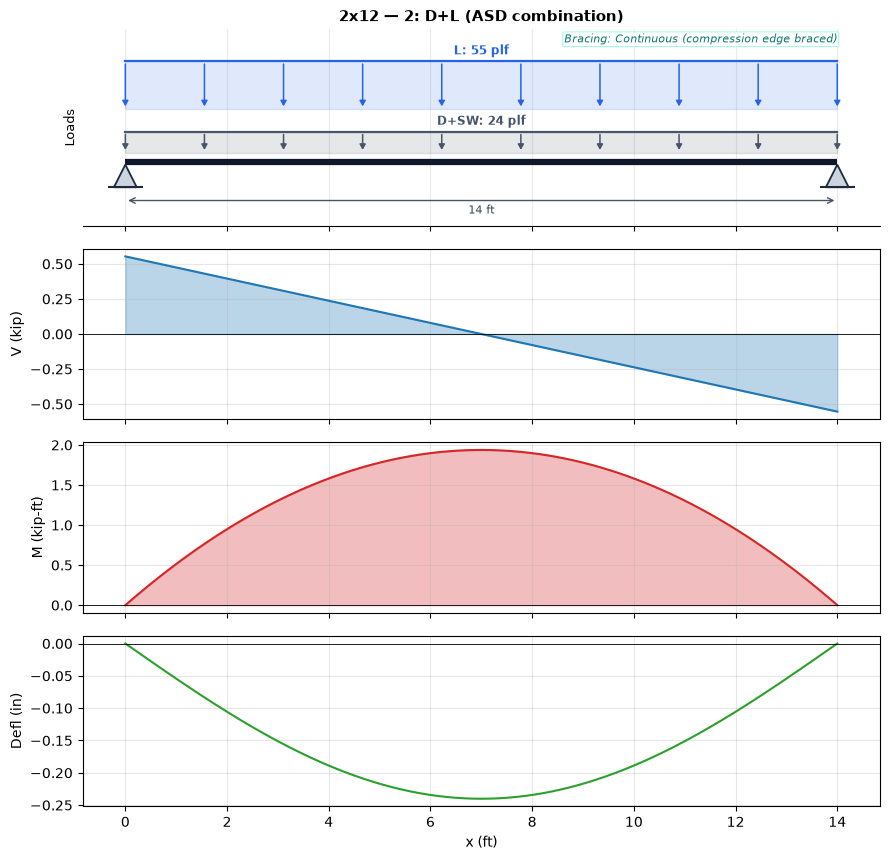

In [8]:
#@title 7. Loads and diagrams (governing bending combination)
from structcalc.beam import plot

name, seg, res, _ = out["governing"]["flex"]
fig = plot(res, title=f"{out['section'].name} — {name} ({method} combination)",
           beam=out["beam"], brace_pts=out["brace_pts"], bracing_note=out["bracing_note"])

In [9]:
#@title 8. Save report as HTML (optional)
save_report = False  #@param {type:"boolean"}
if save_report:
    path = out["report"].save_html(f"wood_beam_{out['section'].name.replace('/', '_')}.html")
    print("saved", path)
    try:
        from google.colab import files
        files.download(path)
    except ImportError:
        pass